# Personalized cardio digital twin: prototype and validation

Pipeline: **population prior** (LightGBM quantiles, `quantile_prediction.ipynb`) →
**lab updates** (Kalman measurement step) → **wearable drift** (change against the user's own
30-day baseline, lagged by biomarker kinetics) → **AHA PREVENT** 10-year risk with uncertainty.

Every model call goes through `src/`, the same code the `/twin/predict` endpoint runs. Only
the simulator lives in this notebook.

Two questions this notebook answers:
- **A. No labs, wearables only.** After 30 days, can we predict how biomarkers change?
- **B. Lab at signup, wearables only later.** Can we still predict the change?

In [1]:
import dataclasses
import warnings
from datetime import date, timedelta

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.components.personalization.biomarker_config import BIOMARKERS
from src.components.personalization.distributions import forward
from src.components.personalization.kalman import effect_path
from sklearn.model_selection import train_test_split

from src.components.prior_model import RANDOM_STATE, TEST_SIZE, PriorModel
from src.components.prevent import PreventInputs, clip_to_validated, prevent_risk
from src.pipeline.train_prior_pipeline import load_training_frame
from src.pipeline.twin_pipeline import biomarker_samples, predict_twin

warnings.filterwarnings("ignore", category=UserWarning)
plt.rcParams["figure.dpi"] = 110

prior = PriorModel.load()
print(prior.metrics.groupby("target")[["test_pinball", "baseline_pinball", "coverage"]].mean().round(3))

         test_pinball  baseline_pinball  coverage
target                                           
egfr            3.375             4.965     0.495
hba1c           0.123             0.198     0.494
hdl             2.745             3.239     0.502
non_hdl         8.381             9.431     0.518
sbp             3.311             3.787     0.493


## Synthetic users

We start from NHANES participants aged 30–79 with every biomarker measured. Each person's
measured values are their **true day-0 levels**. They're drawn from a 20% split made with the
prior's seed. Each prior target split its own non-missing rows, so most of these people are
unseen by the prior, but not all. From there the simulator generates:
- a **true biomarker path**: day-0 level + lagged response to behaviour change + slow random drift.
  The true response uses the configured effect sizes × a per-user multiplier ~ N(1, 0.5), so
  the filter is **not** told the exact truth.
- **daily wearables** with day-to-day noise and about 10% missing days.
- **labs**: truth × (1 + measurement noise at the configured CV).

Behaviour change starts on day 45: more steps, a lower resting HR, and gradual weight loss.
The control scenario has no change.

In [2]:
TARGETS = list(BIOMARKERS)
PROFILE_COLS = ["sex", "age", "race_eth", "height_cm", "weight_kg", "waist_cm", "smoking",
                "told_high_bp", "bp_meds", "told_high_chol", "chol_meds", "diabetes_dx",
                "prediabetes_dx", "insulin", "diabetes_pills"]

frame = load_training_frame()
_, held_out = train_test_split(frame, test_size=TEST_SIZE, random_state=RANDOM_STATE)
cohort = held_out.dropna(subset=TARGETS + ["height_cm", "weight_kg"])
cohort = cohort[cohort["age"].between(30, 79)].reset_index(drop=True)
print("cohort size:", len(cohort))

START = date(2026, 1, 1)
N_DAYS = 180
CHANGE_DAY = 45


def to_profile(row: pd.Series) -> dict:
    profile = {c: (None if pd.isna(row[c]) else row[c]) for c in PROFILE_COLS}
    for c in ("sex", "race_eth"):
        profile[c] = int(profile[c])
    return profile


def simulate_wearables(row, rng, change: bool) -> tuple[pd.DataFrame, dict]:
    days = np.arange(N_DAYS)
    on = (days >= CHANGE_DAY) & change
    behaviour = {
        "steps": rng.uniform(1500, 5000) if change else 0.0,
        "resting_hr": -rng.uniform(0, 4) if change else 0.0,
        "weight_rate": rng.uniform(0.0, 0.05) if change else 0.0,
    }
    base_steps = rng.normal(6000, 1800)
    base_rhr = rng.normal(70, 6)
    base_sleep = rng.normal(6.9, 0.7)
    weight_drop = np.where(on, np.minimum(days - CHANGE_DAY, 90) * behaviour["weight_rate"], 0.0)
    w = pd.DataFrame({
        "date": [START + timedelta(days=int(d)) for d in days],
        "steps": base_steps + on * behaviour["steps"] + rng.normal(0, 1500, N_DAYS),
        "resting_hr": base_rhr + on * behaviour["resting_hr"] + rng.normal(0, 2, N_DAYS),
        "sleep_h": base_sleep + rng.normal(0, 0.6, N_DAYS),
        "weight_kg": row["weight_kg"] - weight_drop + rng.normal(0, 0.4, N_DAYS),
    })
    missing = rng.random(N_DAYS) < 0.10
    w.loc[missing, ["steps", "resting_hr", "sleep_h", "weight_kg"]] = np.nan
    true_deltas = pd.DataFrame({
        "steps": on * behaviour["steps"] / 1000.0,
        "resting_hr": on * behaviour["resting_hr"],
        "sleep_h": 0.0,
        "weight_kg": -weight_drop,
    }, index=pd.date_range(START, periods=N_DAYS, freq="D"))
    return w, true_deltas


def simulate_truth(row, true_deltas, rng) -> pd.DataFrame:
    truth = {}
    for name, spec in BIOMARKERS.items():
        multiplier = max(rng.normal(1.0, 0.5), 0.0)
        true_spec = dataclasses.replace(spec, effects={k: v * multiplier for k, v in spec.effects.items()})
        effect = effect_path(true_spec, true_deltas).to_numpy()
        drift = np.cumsum(rng.normal(0, spec.annual_drift_cv / np.sqrt(365), N_DAYS))
        drift[0] = 0.0
        truth[name] = np.clip((row[name] + effect) * (1 + drift), *spec.clamp)
    return pd.DataFrame(truth, index=[START + timedelta(days=d) for d in range(N_DAYS)])


def draw_labs(truth: pd.DataFrame, lab_days: list[int], rng) -> list[dict]:
    labs = []
    for d in lab_days:
        day = START + timedelta(days=d)
        for name, spec in BIOMARKERS.items():
            value = truth.loc[day, name] * (1 + rng.normal(0, spec.measurement_cv))
            labs.append({"date": day, "biomarker": name, "value": float(value)})
    return labs


SCENARIOS = {
    "A: wearables only": {"labs": [], "change": True},
    "B: lab day 0 + wearables": {"labs": [0], "change": True},
    "C: labs day 0 & 120 + wearables": {"labs": [0, 120], "change": True},
    "D: lab day 0, no behaviour change": {"labs": [0], "change": False},
}

cohort size: 870


## One user, four scenarios

The same person runs through every scenario with `as_of` = day 120 and a 60-day forecast.
Shaded band: 80% interval. Dashed line: truth. Dots: labs.

{'sex': 2, 'age': np.float64(52.0), 'race_eth': 3, 'weight_kg': np.float64(98.4), 'smoking': 'former', 'bp_meds': np.float64(1.0), 'chol_meds': np.float64(0.0)}


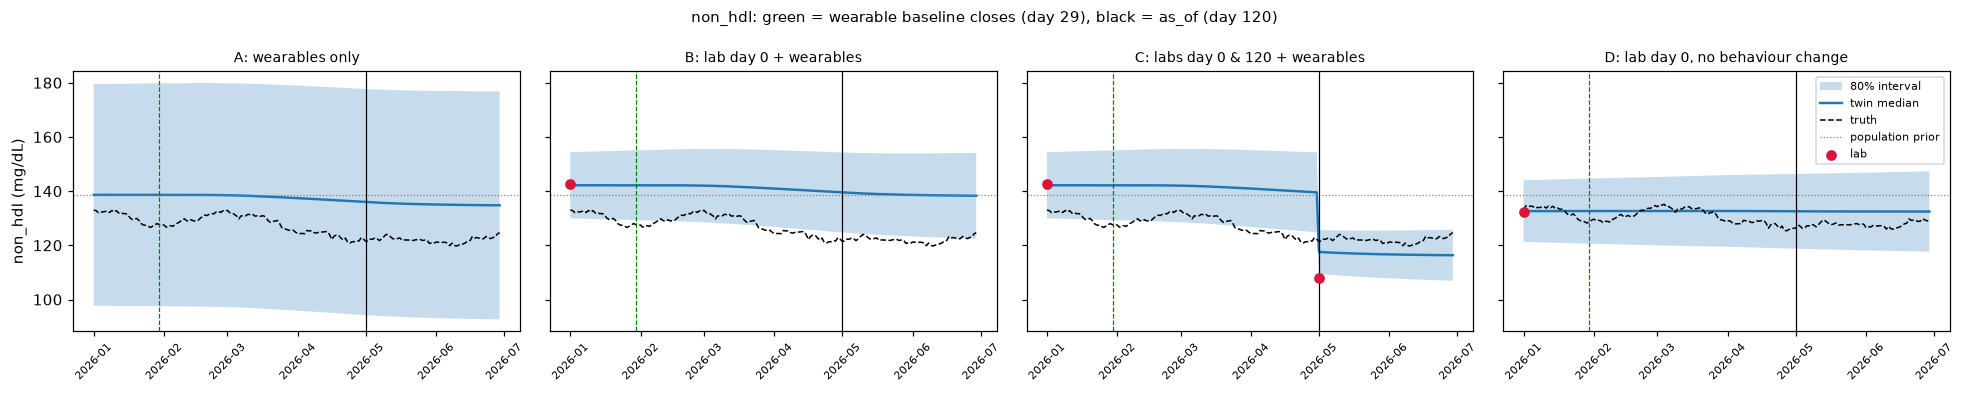

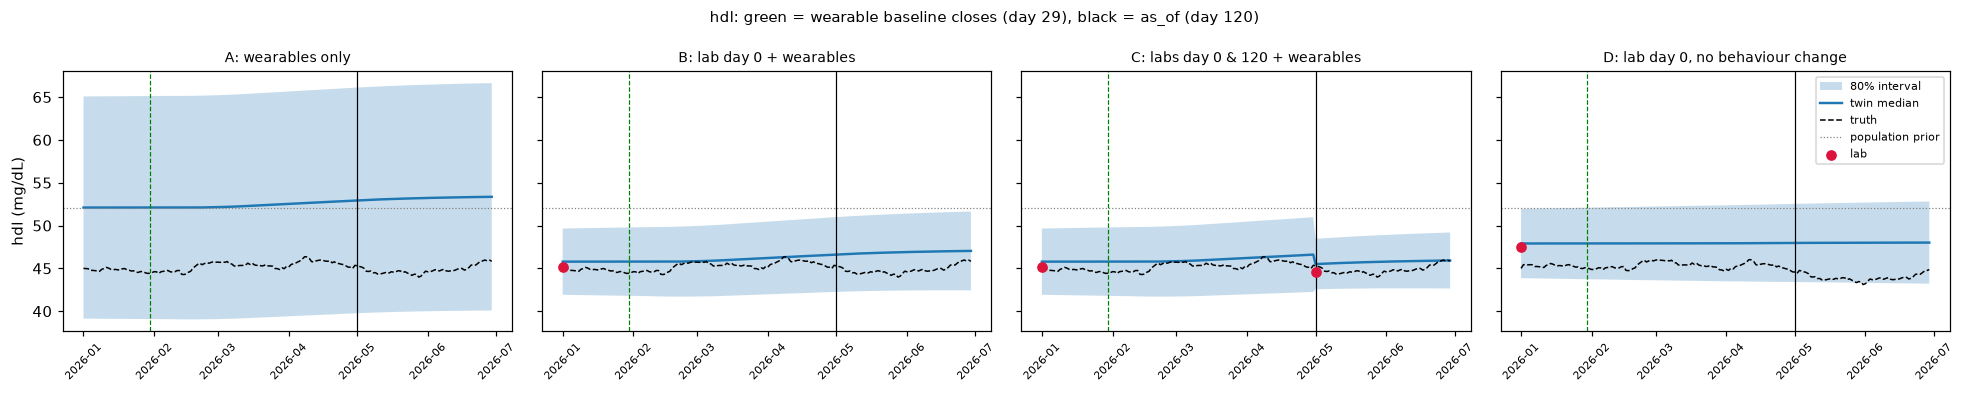

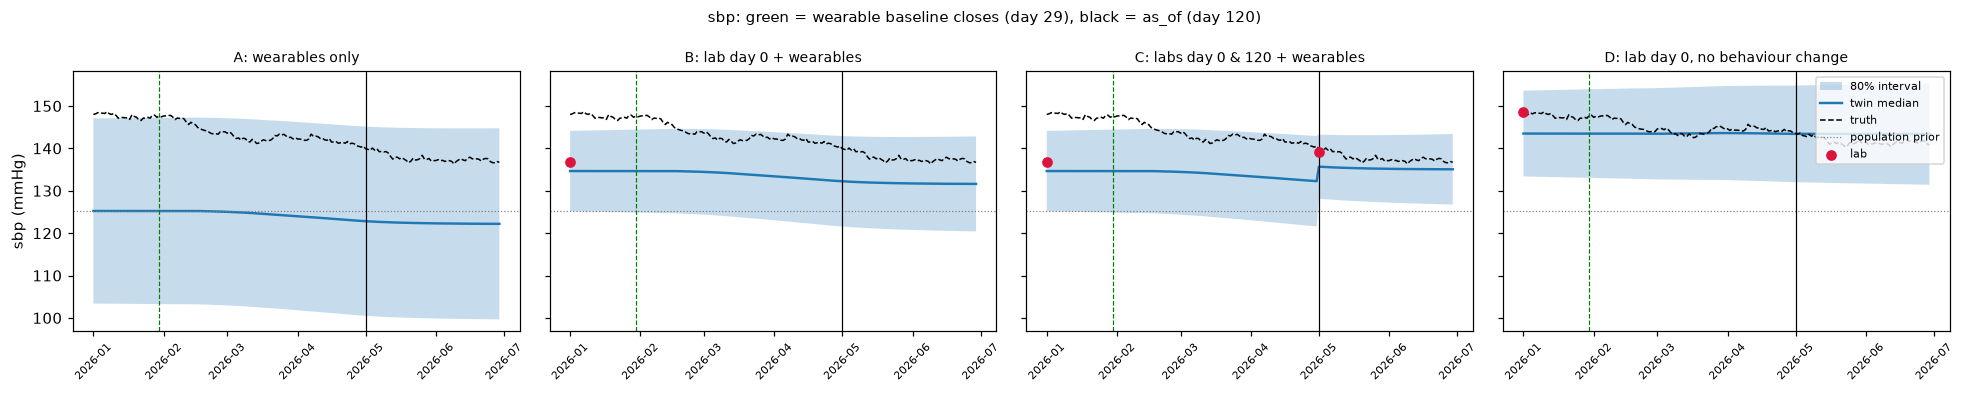

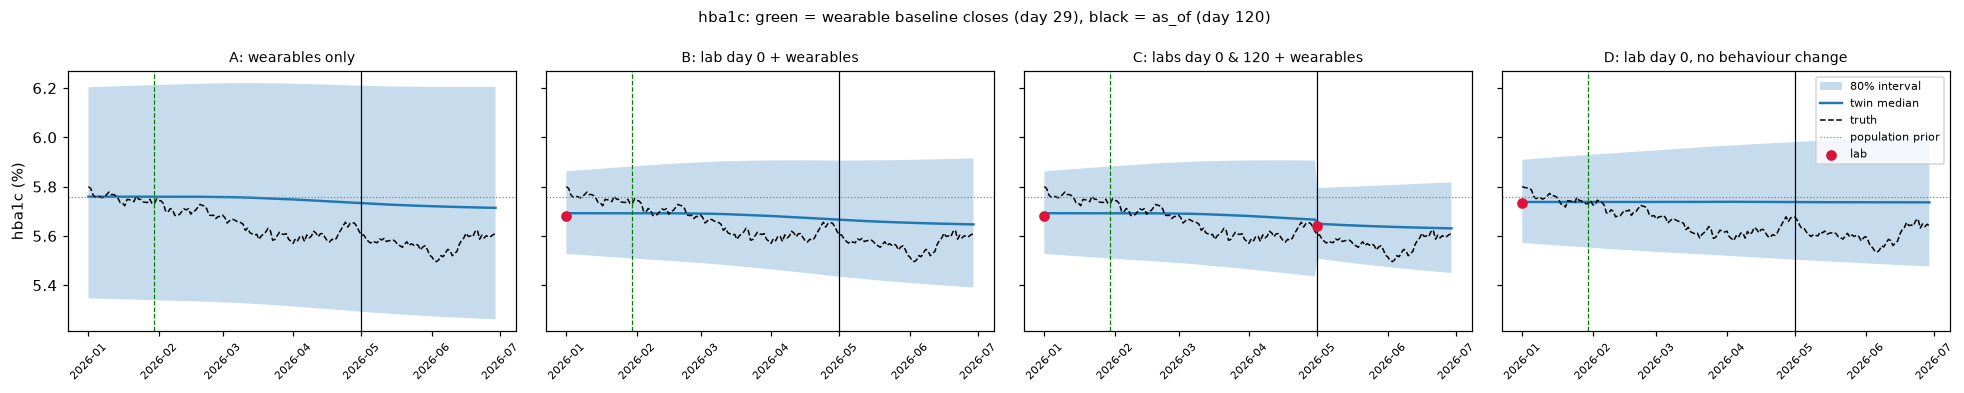

In [3]:
rng = np.random.default_rng(7)
showcase = cohort.iloc[int(rng.integers(len(cohort)))]
profile = to_profile(showcase)
print({k: profile[k] for k in ("sex", "age", "race_eth", "weight_kg", "smoking", "bp_meds", "chol_meds")})

AS_OF = START + timedelta(days=120)
showcase_runs = {}
for label, cfg in SCENARIOS.items():
    srng = np.random.default_rng(11)
    wearables, true_deltas = simulate_wearables(showcase, srng, cfg["change"])
    truth = simulate_truth(showcase, true_deltas, srng)
    labs = draw_labs(truth, cfg["labs"], srng)
    seen = wearables[wearables["date"] <= AS_OF]
    labs_seen = [l for l in labs if l["date"] <= AS_OF]
    twin = predict_twin(prior, profile, labs_seen, seen, as_of=AS_OF, horizon_days=59)
    showcase_runs[label] = dict(twin=twin, truth=truth, labs=labs, wearables=wearables)


def plot_trajectories(biomarker: str):
    fig, axes = plt.subplots(1, len(SCENARIOS), figsize=(18, 3.6), sharey=True)
    for ax, (label, run) in zip(axes, showcase_runs.items()):
        tr = run["twin"].biomarkers[biomarker].trajectory
        x = pd.to_datetime(tr["date"])
        ax.fill_between(x, tr["q10"], tr["q90"], alpha=0.25, label="80% interval")
        ax.plot(x, tr["q50"], lw=1.6, label="twin median")
        ax.plot(pd.to_datetime(run["truth"].index), run["truth"][biomarker], "k--", lw=1, label="truth")
        ax.axhline(run["twin"].prior_quantiles[biomarker][0.5], color="grey", lw=0.8, ls=":", label="population prior")
        lab_pts = [(l["date"], l["value"]) for l in run["labs"] if l["biomarker"] == biomarker]
        if lab_pts:
            ax.scatter(pd.to_datetime([d for d, _ in lab_pts]), [v for _, v in lab_pts], color="crimson", zorder=5, label="lab")
        ax.axvline(pd.Timestamp(START + timedelta(days=29)), color="green", lw=0.8, ls="--")
        ax.axvline(pd.Timestamp(AS_OF), color="black", lw=0.8)
        ax.set_title(label, fontsize=9)
        ax.tick_params(axis="x", labelrotation=45, labelsize=7)
    axes[0].set_ylabel(f"{biomarker} ({BIOMARKERS[biomarker].unit})")
    axes[-1].legend(fontsize=7, loc="upper right")
    fig.suptitle(f"{biomarker}: green = wearable baseline closes (day 29), black = as_of (day 120)", fontsize=10)
    fig.tight_layout()
    plt.show()


for b in ("non_hdl", "hdl", "sbp", "hba1c"):
    plot_trajectories(b)

### Prior vs posterior and uncertainty over time

The left panel compares the prior density with the posterior on `as_of` for scenario B. The
right panel shows posterior SD relative to the prior SD. It collapses at each lab, then slowly
grows back as time passes.

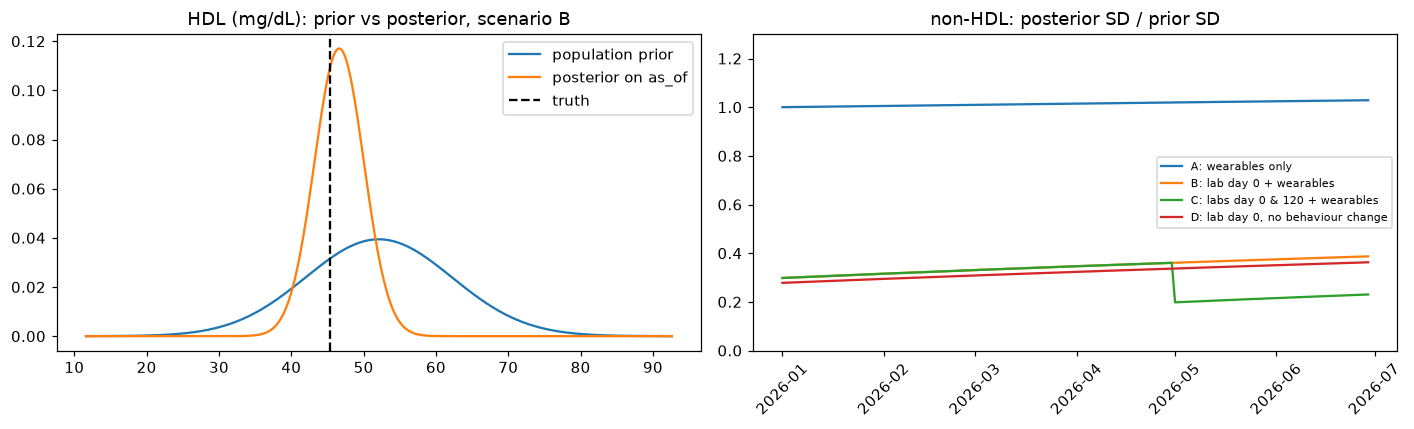

In [4]:
from scipy.stats import norm

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
run = showcase_runs["B: lab day 0 + wearables"]["twin"]
res = run.biomarkers["hdl"]
row = res.trajectory[res.trajectory["date"] == AS_OF].iloc[0]
xs = np.linspace(res.prior_mean - 4 * res.prior_sd, res.prior_mean + 4 * res.prior_sd, 400)
axes[0].plot(xs, norm.pdf(xs, res.prior_mean, res.prior_sd), label="population prior")
axes[0].plot(xs, norm.pdf(xs, row["mean"], row["sd"]), label="posterior on as_of")
axes[0].axvline(showcase_runs["B: lab day 0 + wearables"]["truth"].loc[AS_OF, "hdl"], color="k", ls="--", label="truth")
axes[0].set_title("HDL (mg/dL): prior vs posterior, scenario B")
axes[0].legend()

for label, r in showcase_runs.items():
    tr = r["twin"].biomarkers["non_hdl"].trajectory
    axes[1].plot(pd.to_datetime(tr["date"]), tr["sd"] / r["twin"].biomarkers["non_hdl"].prior_sd, label=label)
axes[1].set_title("non-HDL: posterior SD / prior SD")
axes[1].set_ylim(0, 1.3)
axes[1].legend(fontsize=7)
axes[1].tick_params(axis="x", labelrotation=45)
fig.tight_layout()
plt.show()

### Wearable change against the user's own baseline

Trailing 30-day means for scenario A. The baseline window is days 0–29. The change starts on day 45.

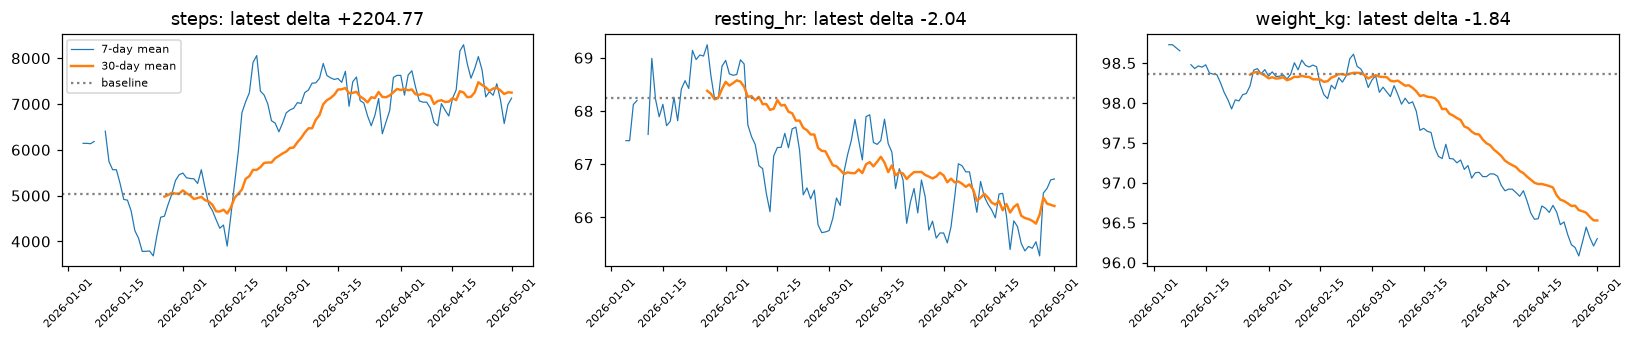

In [5]:
twin_a = showcase_runs["A: wearables only"]["twin"]
rolling = twin_a.wearable.rolling
fig, axes = plt.subplots(1, 3, figsize=(15, 3.2))
for ax, feat in zip(axes, ("steps", "resting_hr", "weight_kg")):
    ax.plot(rolling.index, rolling[f"{feat}_7d"], lw=0.8, label="7-day mean")
    ax.plot(rolling.index, rolling[f"{feat}_30d"], lw=1.6, label="30-day mean")
    if twin_a.wearable.baseline.get(feat) is not None:
        ax.axhline(twin_a.wearable.baseline[feat], color="grey", ls=":", label="baseline")
    ax.set_title(f"{feat}: latest delta {twin_a.wearable.latest_delta.get(feat):+.2f}")
    ax.tick_params(axis="x", labelrotation=45, labelsize=7)
axes[0].legend(fontsize=7)
fig.tight_layout()
plt.show()

### PREVENT 10-year risk: population prior vs personalized

Monte-Carlo samples from each biomarker distribution go through the PREVENT base equations.
These are ported from the official AHA package v1.1.0 and tests check them against its beta
table. "True" risk is PREVENT applied to the simulated true biomarkers on `as_of`.

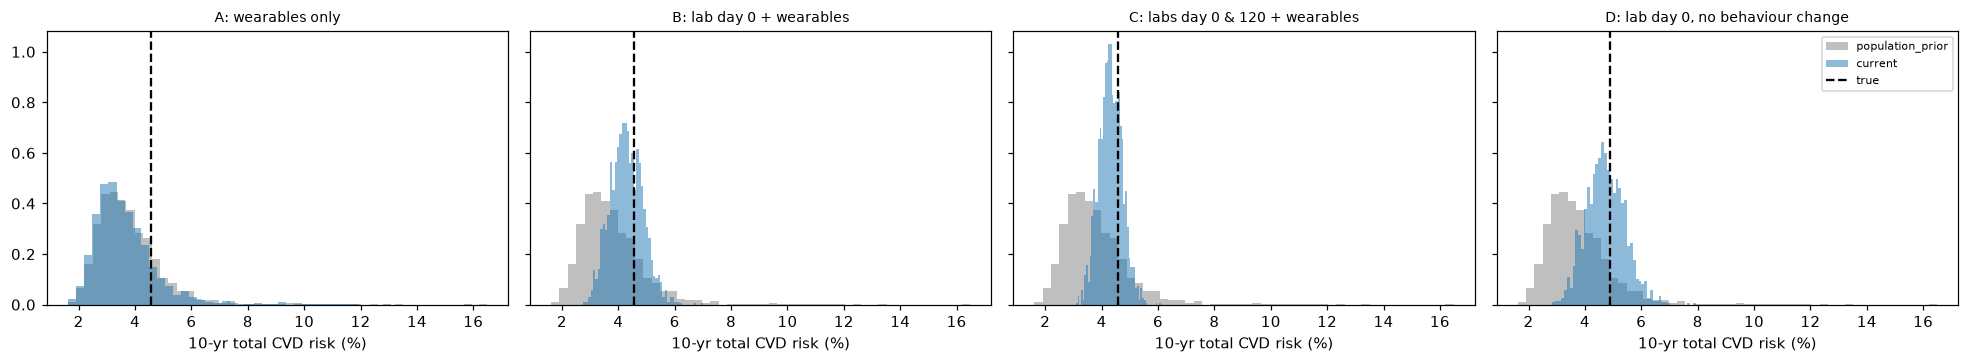

,A: wearables only,B: lab day 0 + wearables,C: labs day 0 & 120 + wearables,"D: lab day 0, no behaviour change"
population_prior total_cvd,3.57,3.57,3.57,3.57
population_prior ascvd,2.02,2.02,2.02,2.02
population_prior heart_failure,2.07,2.07,2.07,2.07
current total_cvd,3.43,4.27,4.31,4.71
current ascvd,1.92,2.45,2.39,2.73
current heart_failure,1.95,2.18,2.20,2.49
forecast total_cvd,3.39,4.20,4.24,4.71
forecast ascvd,1.88,2.41,2.34,2.73
forecast heart_failure,1.94,2.16,2.18,2.49


In [6]:
def true_risk(row, truth_day: pd.Series, weight: float) -> dict:
    diabetic = row["diabetes_dx"] == "yes" or truth_day["hba1c"] >= 6.5
    risk = prevent_risk(PreventInputs(
        age=float(row["age"]), sex=int(row["sex"]),
        total_chol=clip_to_validated("total_chol", truth_day["non_hdl"] + truth_day["hdl"]),
        hdl=clip_to_validated("hdl", truth_day["hdl"]), sbp=clip_to_validated("sbp", truth_day["sbp"]),
        bmi=clip_to_validated("bmi", weight / (row["height_cm"] / 100) ** 2), egfr=truth_day["egfr"],
        diabetes=float(diabetic), smoking=float(row["smoking"] == "current"),
        bp_treated=float(row["bp_meds"] == 1), statin=float(row["chol_meds"] == 1),
    ))
    return {k: float(v) for k, v in risk.items()}


fig, axes = plt.subplots(1, len(SCENARIOS), figsize=(18, 3.4), sharey=True)
for ax, (label, r) in zip(axes, showcase_runs.items()):
    twin = r["twin"]
    if not twin.prevent:
        ax.set_title(f"{label}\n{twin.prevent_note}", fontsize=8)
        continue
    weight = float(r["wearables"].loc[r["wearables"]["date"] <= AS_OF, "weight_kg"].dropna().iloc[-30:].mean())
    truth_value = true_risk(showcase, r["truth"].loc[AS_OF], weight)["total_cvd"]
    for view, color in (("population_prior", "grey"), ("current", "tab:blue")):
        s = biomarker_samples(twin, None if view == "population_prior" else AS_OF, 2000, 0)
        risk = prevent_risk(PreventInputs(
            age=float(showcase["age"]), sex=int(showcase["sex"]),
            total_chol=clip_to_validated("total_chol", s["non_hdl"] + s["hdl"]),
            hdl=clip_to_validated("hdl", s["hdl"]), sbp=clip_to_validated("sbp", s["sbp"]),
            bmi=clip_to_validated("bmi", weight / (showcase["height_cm"] / 100) ** 2), egfr=s["egfr"],
            diabetes=np.where((showcase["diabetes_dx"] == "yes") | (s["hba1c"] >= 6.5), 1.0, 0.0),
            smoking=float(showcase["smoking"] == "current"), bp_treated=float(showcase["bp_meds"] == 1),
            statin=float(showcase["chol_meds"] == 1),
        ))
        ax.hist(risk["total_cvd"] * 100, bins=50, alpha=0.5, color=color, label=view, density=True)
    ax.axvline(truth_value * 100, color="k", ls="--", label="true")
    ax.set_title(label, fontsize=9)
    ax.set_xlabel("10-yr total CVD risk (%)")
axes[-1].legend(fontsize=7)
fig.tight_layout()
plt.show()

pd.DataFrame({label: {f"{view} {o}": v["median"] for view, d in r["twin"].prevent.items() for o, v in d.items()}
              for label, r in showcase_runs.items()}).mul(100).round(2)

## Validation across the cohort

For every user and scenario, filter through day 179 and score against the truth on day 90 and day 179:
- **coverage**: share of truths inside the 80% interval (target 0.80)
- **MAE**: twin median vs truth, compared with the population-prior median vs truth
- **CRPS** (Gaussian, working scale): accuracy and calibration in one number; lower is better
- **innovation z** at the second lab in scenario C: should look like N(0, 1)
- **PREVENT error**: |predicted median − true risk| for prior vs twin

In [7]:
N_USERS = min(300, len(cohort))
EVAL_DAYS = (90, 179)
END = START + timedelta(days=N_DAYS - 1)


def gaussian_crps(mu, sigma, y):
    z = (y - mu) / sigma
    return sigma * (z * (2 * norm.cdf(z) - 1) + 2 * norm.pdf(z) - 1 / np.sqrt(np.pi))


rows, innovations, risk_rows = [], [], []
eval_rng = np.random.default_rng(2026)
for i in range(N_USERS):
    person = cohort.iloc[i]
    person_profile = to_profile(person)
    seed = int(eval_rng.integers(1e9))
    for label, cfg in SCENARIOS.items():
        srng = np.random.default_rng(seed)
        wearables, true_deltas = simulate_wearables(person, srng, cfg["change"])
        truth = simulate_truth(person, true_deltas, srng)
        labs = draw_labs(truth, cfg["labs"], srng)
        twin = predict_twin(prior, person_profile, labs, wearables, as_of=END, horizon_days=0, n_samples=500)
        for name, res in twin.biomarkers.items():
            spec = BIOMARKERS[name]
            tr = res.trajectory.set_index("date")
            for d in EVAL_DAYS:
                day = START + timedelta(days=d)
                y = truth.loc[day, name]
                p = tr.loc[day]
                rows.append({
                    "scenario": label, "biomarker": name, "day": d,
                    "covered": p["q10"] <= y <= p["q90"],
                    "abs_err_twin": abs(p["q50"] - y),
                    "abs_err_prior": abs(twin.prior_quantiles[name][0.5] - y),
                    "crps_twin": gaussian_crps(p["mean"], p["sd"], float(forward(y, spec.transform))),
                    "crps_prior": gaussian_crps(res.prior_mean, res.prior_sd, float(forward(y, spec.transform))),
                })
            if label.startswith("C") and len(res.innovations) == 2:
                innovations.append({"biomarker": name, "z": res.innovations[1].z})
        if twin.prevent:
            weight = float(wearables["weight_kg"].dropna().iloc[-30:].mean())
            true_value = true_risk(person, truth.loc[END], weight)["total_cvd"]
            risk_rows.append({
                "scenario": label,
                "err_prior": abs(twin.prevent["population_prior"]["total_cvd"]["median"] - true_value),
                "err_twin": abs(twin.prevent["current"]["total_cvd"]["median"] - true_value),
            })

results = pd.DataFrame(rows)
summary = results.groupby(["scenario", "biomarker", "day"]).agg(
    coverage_80=("covered", "mean"),
    mae_prior=("abs_err_prior", "mean"),
    mae_twin=("abs_err_twin", "mean"),
    crps_prior=("crps_prior", "mean"),
    crps_twin=("crps_twin", "mean"),
)
summary["mae_reduction_%"] = 100 * (1 - summary["mae_twin"] / summary["mae_prior"])
summary.round(3)

coverage_80  mae_prior  \
scenario                          biomarker day                           
A: wearables only                 egfr      90         0.837     10.845   
                                            179        0.823     10.975   
                                  hba1c     90         0.823      0.413   
                                            179        0.817      0.431   
                                  hdl       90         0.813      9.430   
                                            179        0.817      9.691   
                                  non_hdl   90         0.813     26.789   
                                            179        0.837     27.596   
                                  sbp       90         0.843     10.913   
                                            179        0.827     11.667   
B: lab day 0 + wearables          egfr      90         0.827     10.845   
                                            179        0.823     10.975   
                                  hba1c     90         0.830      0.413   
                                            179        0.790      0.431   
                                  hdl       90         0.783      9.430   
                                            179        0.767      9.691   
                                  non_hdl   90         0.787     26.789   
                                            179        0.760     27.596   
                                  sbp       90         0.783     10.913   
                                            179        0.787     11.667   
C: labs day 0 & 120 + wearables   egfr      90         0.827     10.845   
                                            179        0.823     10.975   
                                  hba1c     90         0.830      0.413   
                                            179        0.810      0.431   
                                  hdl       90         0.783      9.430   
                                            179        0.763      9.691   
                                  non_hdl   90         0.787     26.789   
                                            179        0.750     27.596   
                                  sbp       90         0.783     10.913   
                                            179        0.793     11.667   
D: lab day 0, no behaviour change egfr      90         0.817     10.885   
                                            179        0.807     10.991   
                                  hba1c     90         0.747      0.411   
                                            179        0.797      0.424   
                                  hdl       90         0.780      9.370   
                                            179        0.793      9.443   
                                  non_hdl   90         0.763     26.519   
                                            179        0.743     26.948   
                                  sbp       90         0.797     10.625   
                                            179        0.780     11.112   

                                                 mae_twin  crps_prior  \
scenario                          biomarker day                         
A: wearables only                 egfr      90     10.845       0.100   
                                            179    10.975       0.101   
                                  hba1c     90      0.413       0.049   
                                            179     0.426       0.051   
                                  hdl       90      9.393       6.962   
                                            179     9.548       7.120   
                                  non_hdl   90     26.654      19.336   
                                            179    27.023      19.678   
                                  sbp       90     10.789       7.902   
                                            179    11.228       8.354   
B: lab day 0 + wearabl

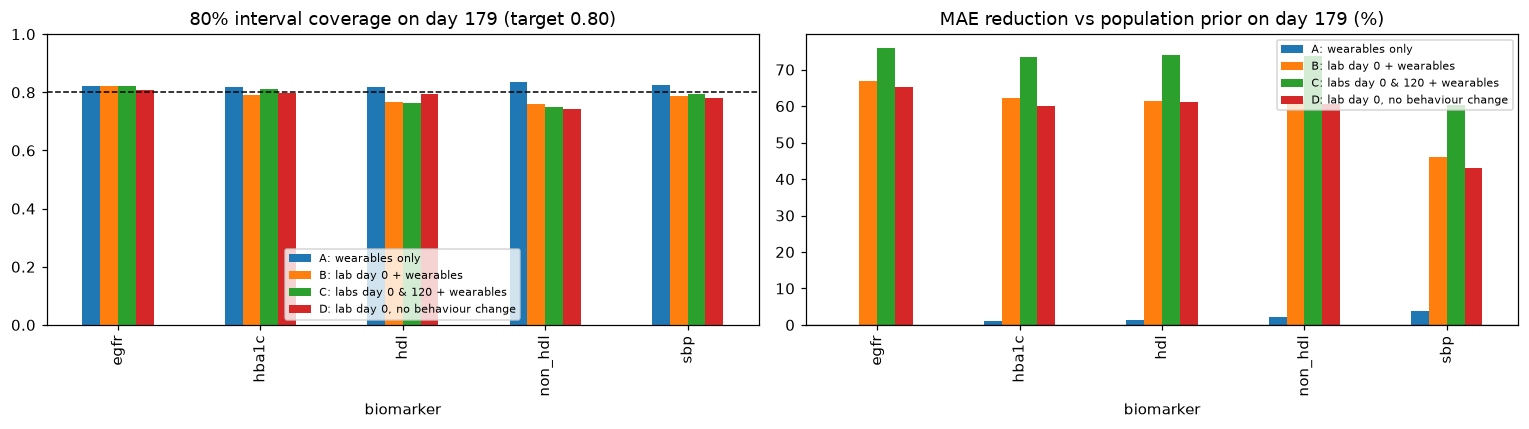

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
pivot_cov = summary.reset_index().query("day == 179").pivot(index="biomarker", columns="scenario", values="coverage_80")
pivot_cov.plot.bar(ax=axes[0])
axes[0].axhline(0.8, color="k", ls="--", lw=1)
axes[0].set_ylim(0, 1)
axes[0].set_title("80% interval coverage on day 179 (target 0.80)")
axes[0].legend(fontsize=7)

pivot_mae = summary.reset_index().query("day == 179").pivot(index="biomarker", columns="scenario", values="mae_reduction_%")
pivot_mae.plot.bar(ax=axes[1])
axes[1].axhline(0, color="k", lw=0.8)
axes[1].set_title("MAE reduction vs population prior on day 179 (%)")
axes[1].legend(fontsize=7)
fig.tight_layout()
plt.show()

           mean   std  count
biomarker                   
egfr      -0.15  1.02    300
hba1c     -0.05  1.00    300
hdl        0.15  1.03    300
non_hdl    0.06  1.13    300
sbp       -0.00  1.03    300


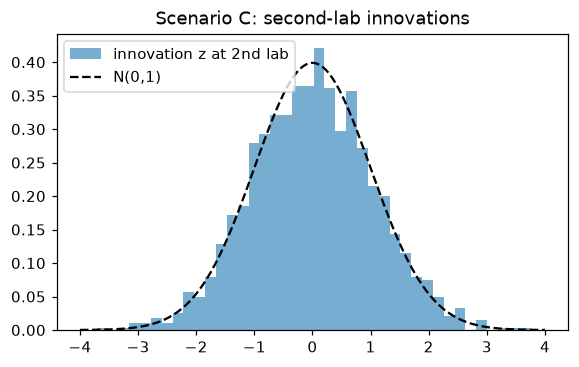

,MAE prior (pct-pts),MAE twin (pct-pts)
scenario,,
A: wearables only,1.503,1.490
B: lab day 0 + wearables,1.503,0.607
C: labs day 0 & 120 + wearables,1.503,0.448
"D: lab day 0, no behaviour change",1.619,0.729


In [9]:
z = pd.DataFrame(innovations)
print(z.groupby("biomarker")["z"].agg(["mean", "std", "count"]).round(2))
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(z["z"], bins=40, density=True, alpha=0.6, label="innovation z at 2nd lab")
xs = np.linspace(-4, 4, 200)
ax.plot(xs, norm.pdf(xs), "k--", label="N(0,1)")
ax.legend()
ax.set_title("Scenario C: second-lab innovations")
plt.show()

risk = pd.DataFrame(risk_rows)
risk_summary = risk.groupby("scenario")[["err_prior", "err_twin"]].mean().mul(100)
risk_summary.columns = ["MAE prior (pct-pts)", "MAE twin (pct-pts)"]
risk_summary.round(3)

## Reading the results and limits

- **Scenario A (wearables only).** The level stays anchored to the population prior, so the
  absolute error barely moves. What the twin adds is the *direction and size of change*, which
  starts after the 30-day baseline closes. Intervals stay wide, flagged `basis="estimated"` and
  `confidence="low"`.
- **Scenario B (lab at signup, wearables later).** The day-0 lab anchors the level. The wearable
  change measured after day 30 then moves the estimate. This is the case where personalization
  pays off most.
- **Scenario C.** The second lab re-anchors the level. Its innovation z-scores show whether the
  effect sizes and process noise are calibrated. Mean ≠ 0 means biased effects. SD > 1 means
  overconfidence.
- **Limits.** Wearable effect sizes come from the literature (`biomarker_config.py`) and are not
  learned. This validation is on *simulated* users, so it checks that the machinery is
  self-consistent and calibrated when its assumptions roughly hold, not that real biology
  matches. Real validation needs paired data: labs at two or more time points plus wearables in
  between. Once that exists, fit per-user effect sizes with Bayesian linear regression, shrunk
  toward the literature values.